# Predicting mobile video QoE (MOS) on the PoQeMoN dataset

**Objective.** Compare supervised models that predict the Mean Opinion Score (MOS, 1–5) of a mobile YouTube
session from the QoE influence factors in the PoQeMoN dataset, tune their hyperparameters with a systematic grid
search, and evaluate the selected model on a held-out test set.

**Structure** (mirrors the report):

1. Setup and configuration — seeds, paths, protocol constants
2. Data — source, feature groups, sanity checks
3. Exploratory analysis — target, distributions, relationships, user structure
4. Experimental protocol — feature sets, split, cross-validation, metrics, preprocessing
5. Models and hyperparameter grids
6. Results — model comparison, hyperparameter sensitivity, final test evaluation, feature importance
7. Limitations and next steps
8. Reproducibility

**How to run.** From the repository root: `jupyter nbconvert --to notebook --execute --inplace notebooks/poqemon-qoe-project.ipynb`
(or *Restart & Run All*). The notebook runs top to bottom with no manual changes. Figures are written to
`report/figures/` and result tables to `results/` for use in the report.

## 1. Setup and configuration

In [1]:
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost as xgb
import random
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, mean_absolute_error)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# ---- Protocol constants (everything that affects results is set here) ----
## Fixed random seed to ensure reproducible experiments

SEED = 42
DATA_URL = "https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv"
N_OUTER_SPLITS = 5      # one of 5 folds is held out as test set -> 80% train / 20% test
CV_FOLDS = 5            # inner cross-validation folds used by GridSearchCV
GROUP_BY_USER = True    # keep all sessions of a user in the same fold (see Section 4)
SELECTION_METRIC = "f1_macro"
# project path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() #identifie le dossier principal du projet
DATA_PATH = ROOT / "data" / "pokemon.csv" ## Dataset location
FIG_DIR = ROOT / "report" / "figures" ## Folder for saving figures
RESULTS_DIR = ROOT / "results" ## Folder for saving results

# Create output folders if they do not already exist
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
random.seed(SEED)
np.random.seed(SEED) #Ensure reproducible random operation
sns.set_theme(style="whitegrid") # Set the default visualization style
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 100, "savefig.dpi": 200,
                     "savefig.bbox": "tight"}) # Default figure size

# Function to save figures in the report/figures folder
def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png",
                dpi=200, bbox_inches="tight")
    
## Display library versions for reproducibility
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgb.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.15 | numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | xgboost 3.4.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
## 2. Data



The dataset used in this project is `pokemon.csv`, obtained from the [PoQeMoN QoE dataset](https://github.com/Lamyne/Poqemon-QoE-Dataset) (Amour et al.). It was collected through a crowdsourcing campaign in which 181 testers watched YouTube videos on 9 Android devices across 4 French mobile operators and rated their viewing experience.

According to the repository documentation, the dataset contains several groups of Quality of Experience (QoE) influence factors:

| Group | Columns | Description |
|---|---|---|
| — | `id`, `user_id` | Session and tester identifiers |
| QoA | `QoA_VLC*`, `QoA_BUFFERING*` | Application-level measurements, including resolution, bitrate, frame rate, dropped frames, audio quality and buffering events |
| QoS | `QoS_type`, `QoS_operator` | Network technology and mobile operator |
| QoD | `QoD_model`, `QoD_os-version`, `QoD_api-level` | Device characteristics |
| QoU | `QoU_sex`, `QoU_age`, `QoU_Ustedy` | User profile information |
| QoF | `QoF_begin`, `QoF_shift`, `QoF_audio`, `QoF_video` | Subjective user ratings of start-up, shifting, audio and video quality |
| Target | `MOS` | Overall Mean Opinion Score, ranging from 1 (Bad) to 5 (Excellent) |

The prediction target is `MOS`, an ordinal variable with five possible values. Since the QoF variables contain additional subjective ratings, they will be handled separately to investigate their potential influence on prediction performance and avoid relying on information that may overlap with the overall MOS score.

The dataset is downloaded once and cached locally in the `data/` directory to ensure consistent access across experiments.

In [3]:
# Download the dataset only if it is not already stored locally
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]} sessions, {df.shape[1]} columns")
df.head()

1543 sessions, 23 columns


,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


In [4]:
# Create a summary table to check the quality and structure of the dataset
checks = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
})
# Display the total number of missing values in the dataset
# Also count duplicate sessions after excluding the ID column
print(f"Missing values: {df.isna().sum().sum()} | "
      f"duplicate sessions (ignoring id): {df.drop(columns='id').duplicated().sum()}")
checks

Missing values: 0 | duplicate sessions (ignoring id): 1


,dtype,n_unique,n_missing
id,int64,1543,0
user_id,int64,181,0
QoA_VLCresolution,int64,3,0
QoA_VLCbitrate,float64,1535,0
QoA_VLCframerate,float64,309,0
QoA_VLCdropped,int64,35,0
QoA_VLCaudiorate,float64,193,0
QoA_VLCaudioloss,int64,13,0
QoA_BUFFERINGcount,int64,9,0
QoA_BUFFERINGtime,int64,1327,0


In [5]:
# Generate descriptive statistics for all numerical columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,1543.0,924.26,525.49,52.0,472.50,897.00,1298.50,2077.00
user_id,1543.0,98.13,50.67,1.0,53.00,117.00,135.00,181.00
QoA_VLCresolution,1543.0,354.57,25.94,16.0,360.00,360.00,360.00,360.00
QoA_VLCbitrate,1543.0,520.52,350.96,0.0,307.67,474.00,661.49,3918.29
QoA_VLCframerate,1543.0,25.00,6.69,0.0,24.73,25.32,29.80,31.32
QoA_VLCdropped,1543.0,1.22,5.62,0.0,0.00,0.00,1.00,107.00
QoA_VLCaudiorate,1543.0,40.38,9.12,0.0,43.78,44.15,44.47,46.00
QoA_VLCaudioloss,1543.0,0.24,1.13,0.0,0.00,0.00,0.00,14.00
QoA_BUFFERINGcount,1543.0,1.39,0.90,1.0,1.00,1.00,2.00,10.00
QoA_BUFFERINGtime,1543.0,6164.18,15032.23,683.0,2010.50,2719.00,4067.00,329271.00


In [6]:
# Display the number of observations for each MOS class
print("MOS distribution:")
print(df["MOS"].value_counts().sort_index())

# Display the percentage of each MOS class
print("\nMOS distribution (%):")
print((df["MOS"].value_counts(normalize=True).sort_index() * 100).round(2))

MOS distribution:
MOS
1     93
2    118
3    246
4    784
5    302
Name: count, dtype: int64

MOS distribution (%):
MOS
1     6.03
2     7.65
3    15.94
4    50.81
5    19.57
Name: proportion, dtype: float64


## 3. Exploratory analysis

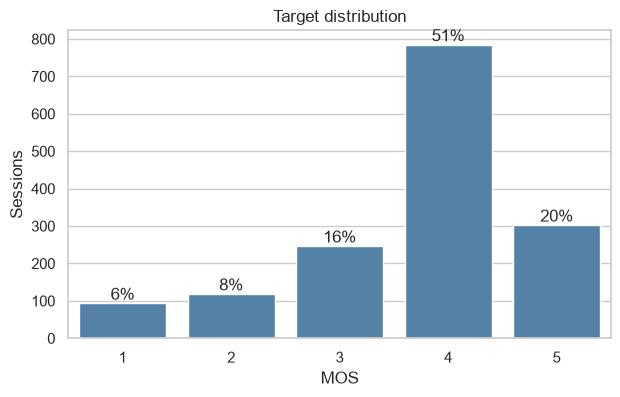

Majority class (MOS=4) share: 50.8%


In [7]:
mos_counts = df["MOS"].value_counts().sort_index()
# Create the figure and plotting area

fig, ax = plt.subplots(figsize=(7, 4))
# Create a bar chart showing the number of sessions per MOS class

sns.barplot(x=mos_counts.index, y=mos_counts.values, color="steelblue", ax=ax)
for i, v in enumerate(mos_counts.values):
    ax.text(i, v + 10, f"{v / len(df):.0%}", ha="center")
ax.set(xlabel="MOS", ylabel="Sessions", title="Target distribution")
# Save the figure
save_fig(fig, "mos_distribution")

# Display the figure
plt.show()

# Close the figure after displaying it
plt.close(fig)
print(f"Majority class (MOS={mos_counts.idxmax()}) share: {mos_counts.max() / len(df):.1%}")

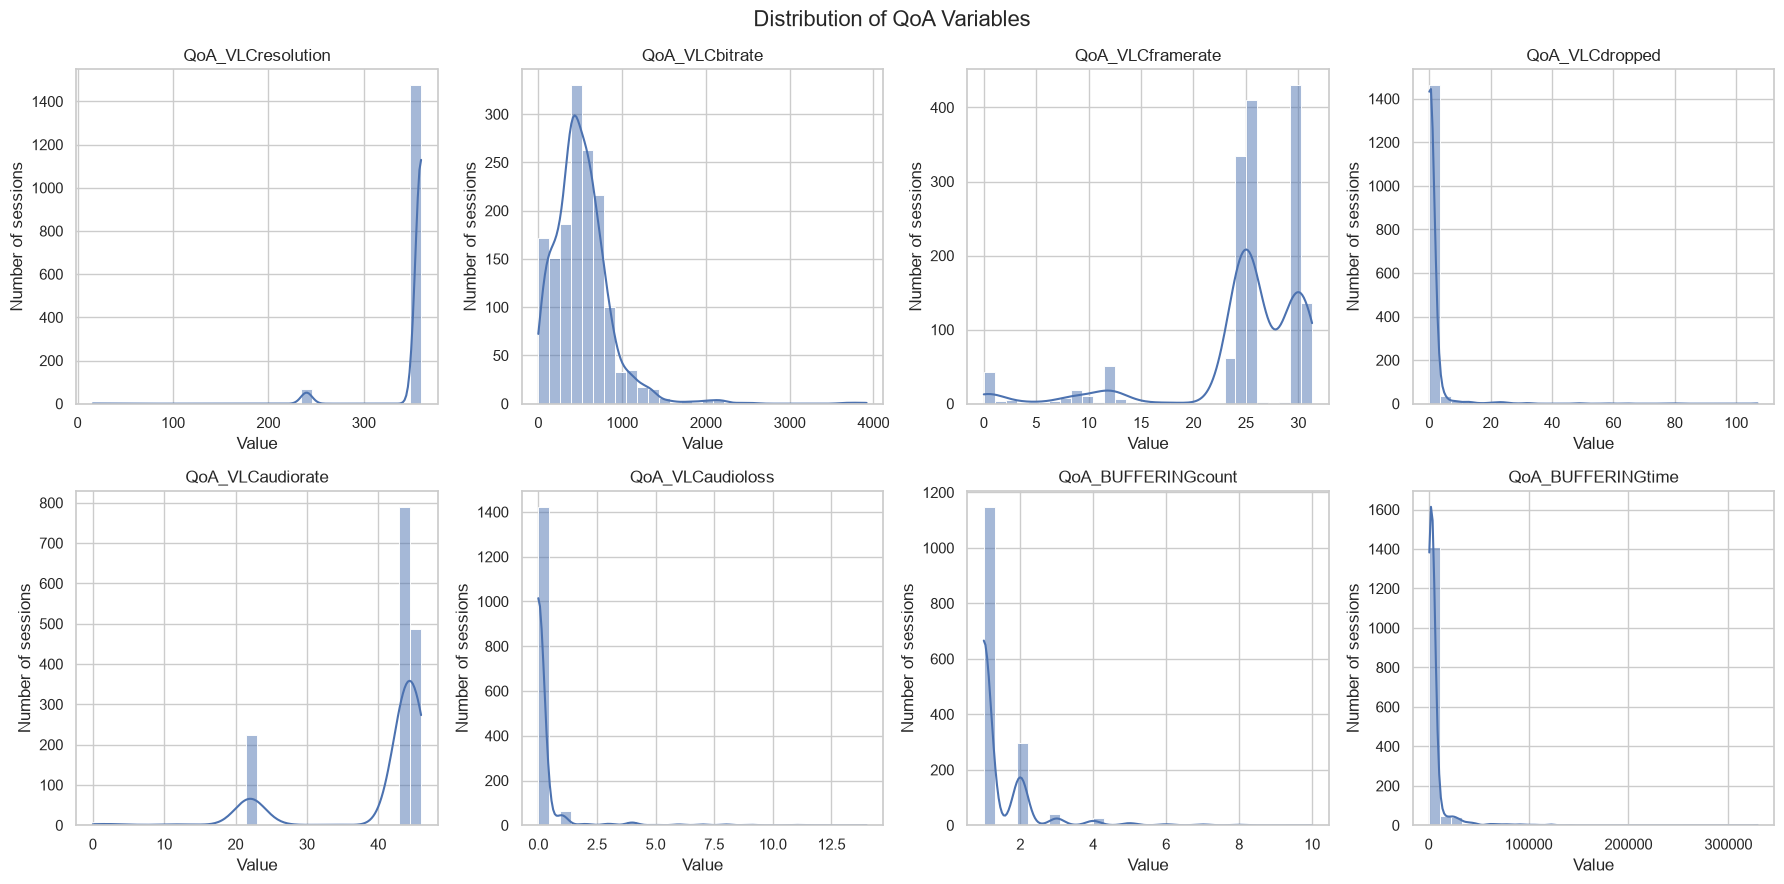

In [8]:
# Select numerical QoA variables
measure_cols = df.select_dtypes(include="number").filter(regex=r"^QoA_").columns

# Create a grid of histograms
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Plot each QoA variable
for ax, col in zip(axes.flat, measure_cols):

    sns.histplot(df[col], bins=30, kde=True, ax=ax)

    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of sessions")

# Add an overall title
fig.suptitle("Distribution of QoA Variables", fontsize=16)

# Adjust layout
fig.tight_layout()

# Save and display the figure
save_fig(fig, "qoa_distributions")
plt.show()
plt.close(fig)

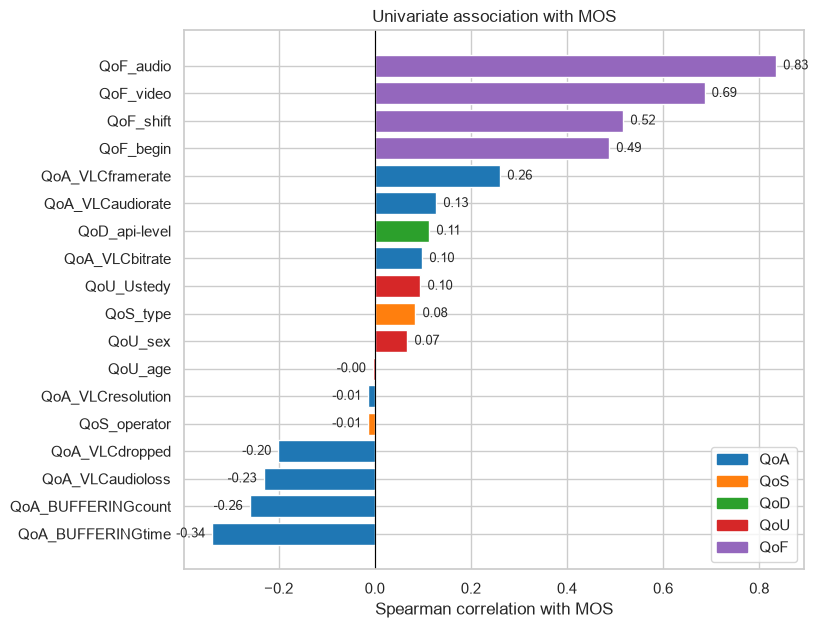

In [9]:
# Spearman correlation: MOS is ordinal and several features are heavy-tailed
# Extract the feature group from the column name
group_of = lambda c: c.split("_")[0]
# Select numerical features and exclude identifiers and target
num_features = df.drop(columns=["id", "user_id", "MOS"]).select_dtypes("number").columns
# Calculate Spearman correlation between each feature and MOS

corr = df[num_features].corrwith(df["MOS"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
# Assign a different color to each feature group
palette = dict(zip(["QoA", "QoS", "QoD", "QoU", "QoF"], sns.color_palette("tab10", 5)))
ax.barh(corr.index, corr.values, color=[palette[group_of(c)] for c in corr.index])
ax.set(xlabel="Spearman correlation with MOS", title="Univariate association with MOS")
# Create the legend 
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=palette.keys(), loc="lower right")

# Add a vertical reference line at zero
ax.axvline(0, color="black", linewidth=0.8)

# Display correlation values next to each bar
for i, value in enumerate(corr.values):
    offset = 0.015 if value >= 0 else -0.015
    alignment = "left" if value >= 0 else "right"

    ax.text(
        value + offset,
        i,
        f"{value:.2f}",
        va="center",
        ha=alignment,
        fontsize=9
    )
save_fig(fig, "spearman_with_mos")
plt.show()

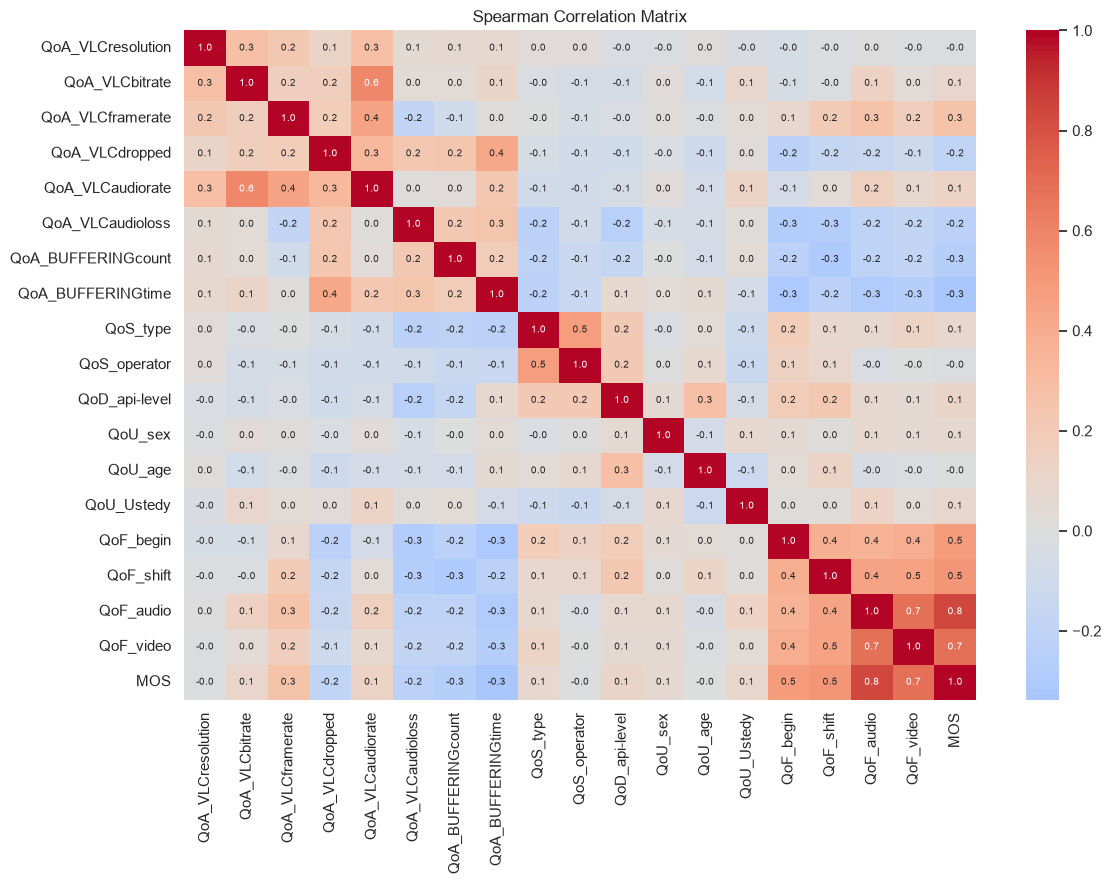

In [10]:
# Create the figure
fig, ax = plt.subplots(figsize=(12, 9))

# Select numerical features and include the target variable (MOS)
selected_features = num_features.tolist() + ["MOS"]

# Calculate the Spearman correlation matrix
corr_matrix = df[selected_features].corr(method="spearman")

# Create the correlation heatmap
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",              # Set the color palette
    center=0,                     # Center the color scale at zero
    annot=True,                   # Display correlation values
    fmt=".1f",                    # Display values with one decimal place
    annot_kws={"size": 7},         # Set annotation font size
    ax=ax
)

# Add the chart title
ax.set_title("Spearman Correlation Matrix")

# Adjust the layout
fig.tight_layout()

# Save and display the figure
save_fig(fig, "spearman_matrix")
plt.show()
plt.close(fig)

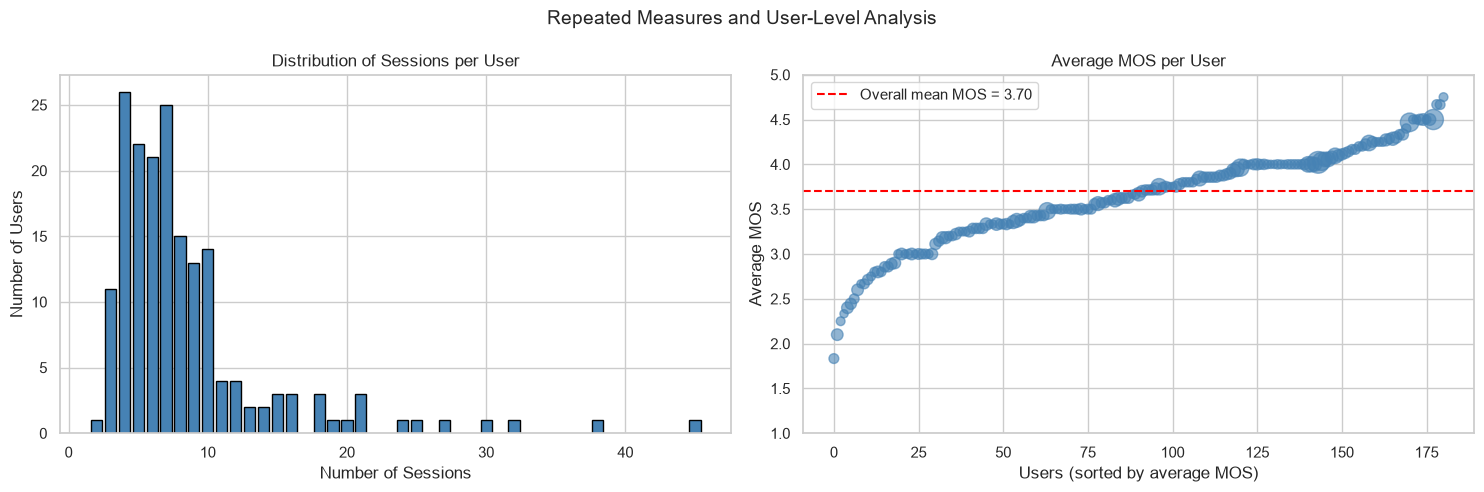

Number of users: 181
Total sessions: 1543
Average sessions per user: 8.52
Median sessions per user: 7
Between-user share of total MOS variation (eta-squared): 24.5%


In [11]:
# Group sessions by user and calculate MOS statistics
per_user = df.groupby("user_id")["MOS"].agg(
    n_sessions="size",
    mean_MOS="mean",
    std_MOS="std"
)

# Calculate the proportion of MOS variance associated with differences between users
overall_mean = df["MOS"].mean()

ss_total = ((df["MOS"] - overall_mean) ** 2).sum()

ss_between = (
    per_user["n_sessions"] *
    (per_user["mean_MOS"] - overall_mean) ** 2
).sum()

eta_squared = ss_between / ss_total

# Create a figure with two visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot the number of sessions contributed by each user
session_counts = per_user["n_sessions"].value_counts().sort_index()

axes[0].bar(
    session_counts.index,
    session_counts.values,
    color="steelblue",
    edgecolor="black"
)

axes[0].set(
    title="Distribution of Sessions per User",
    xlabel="Number of Sessions",
    ylabel="Number of Users"
)

# Sort users by their average MOS
sorted_users = per_user.sort_values("mean_MOS").reset_index(drop=True)

# Set point sizes according to the number of sessions
point_sizes = 20 + 5 * sorted_users["n_sessions"]

# Plot each user's average MOS
axes[1].scatter(
    range(len(sorted_users)),
    sorted_users["mean_MOS"],
    s=point_sizes,
    alpha=0.6,
    color="steelblue"
)

# Add the overall average MOS
axes[1].axhline(
    overall_mean,
    color="red",
    linestyle="--",
    label=f"Overall mean MOS = {overall_mean:.2f}"
)

axes[1].set(
    title="Average MOS per User",
    xlabel="Users (sorted by average MOS)",
    ylabel="Average MOS",
    ylim=(1, 5)
)

axes[1].legend()

# Add an overall figure title
fig.suptitle("Repeated Measures and User-Level Analysis", fontsize=14)

# Adjust the layout
fig.tight_layout()

# Save and display the figure
save_fig(fig, "user_structure")
plt.show()
plt.close(fig)

# Display summary statistics
print(f"Number of users: {len(per_user)}")
print(f"Total sessions: {per_user['n_sessions'].sum()}")
print(f"Average sessions per user: {per_user['n_sessions'].mean():.2f}")
print(f"Median sessions per user: {per_user['n_sessions'].median():.0f}")
print(f"Between-user share of total MOS variation (eta-squared): {eta_squared:.1%}")


In [12]:
# Group sessions by device model and calculate MOS statistics
cat_summary = df.groupby("QoD_model")["MOS"].agg(["size", "mean"])

# Sort device models by the number of sessions
cat_summary = cat_summary.sort_values("size", ascending=False)

# Display the results rounded to two decimal places
cat_summary.round(2)

,size,mean
QoD_model,,
D5803,576,3.85
GT-I9195,338,3.74
GT-I9300,181,3.66
HTC One X+,159,3.33
SM-G900F,112,3.72
ARCHOS 101G9,55,2.96
Nexus 4,55,3.64
SM-N9005,37,3.97
HTC One_M8,24,3.79


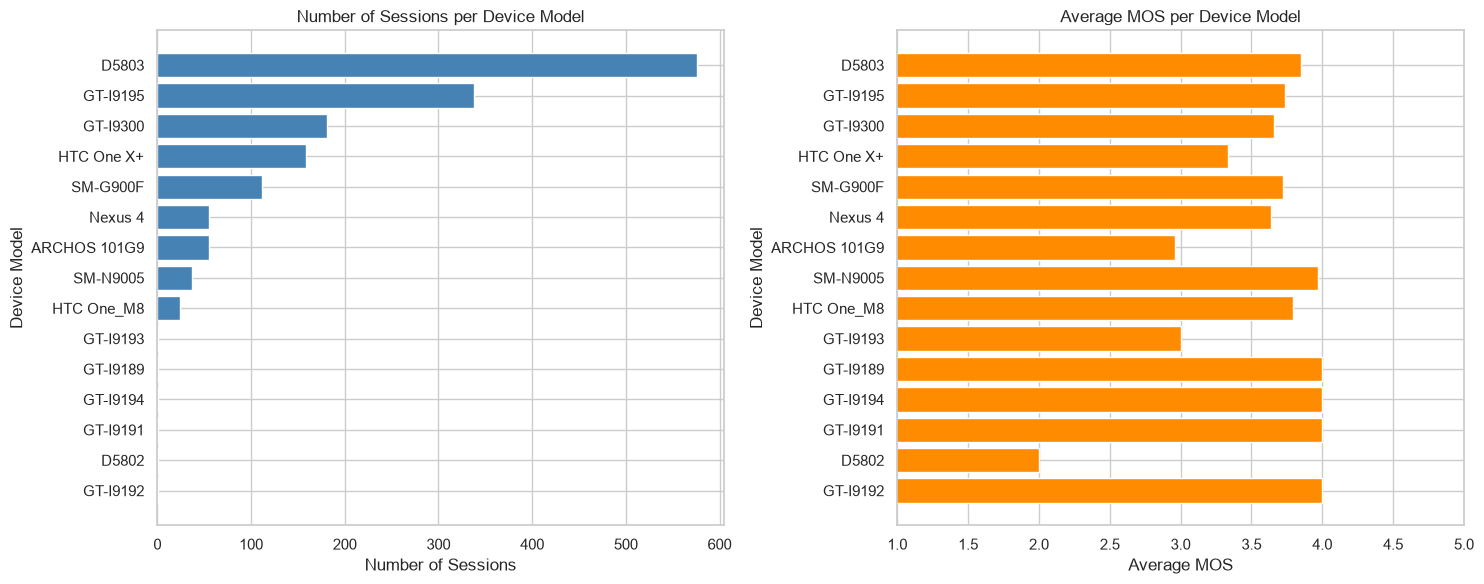

In [13]:
# Sort device models by the number of sessions
cat_summary = cat_summary.sort_values("size", ascending=True)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot the number of sessions per device
axes[0].barh(
    cat_summary.index,
    cat_summary["size"],
    color="steelblue"
)
axes[0].set(
    title="Number of Sessions per Device Model",
    xlabel="Number of Sessions",
    ylabel="Device Model"
)

# Plot the average MOS per device
axes[1].barh(
    cat_summary.index,
    cat_summary["mean"],
    color="darkorange"
)
axes[1].set(
    title="Average MOS per Device Model",
    xlabel="Average MOS",
    ylabel="Device Model",
    xlim=(1, 5)
)

# Adjust the layout
fig.tight_layout()

# Save and display the figure
save_fig(fig, "device_model_analysis")
plt.show()
plt.close(fig)

### EDA findings and how they guide the modelling

1. **Clean data, imbalanced ordinal target.** The dataset contains no missing values and one duplicated session. MOS = 4 represents approximately 51% of all sessions, while MOS 1 and 2 together represent approximately 14%. Therefore, we report a majority-class dummy baseline, use **macro-F1** as our primary model-selection metric to give equal importance to all five classes, and report **MAE** as a complementary metric to account for the ordinal nature of MOS.

2. **QoF features show the strongest association with MOS.** The four subjective user-feedback ratings have the strongest Spearman correlations with MOS (approximately 0.5–0.85). Since these ratings are collected alongside MOS, they may not be available in a real-world prediction scenario. We therefore distinguish between two feature sets: one excluding QoF (objective/measurable features) and another including QoF, to evaluate the additional predictive information they provide.

3. **Application-level measurements show stronger associations with MOS.** Among the measurable factors, buffering time, buffering count, audio loss and dropped frames show negative associations with MOS, while frame rate and audio rate show positive associations. Network and device-related variables generally show weaker univariate associations. However, weak individual correlations do not necessarily mean that these variables are unhelpful when combined with other features.

4. **Some measurements are strongly right-skewed.** Buffering time, dropped frames and audio loss exhibit heavy-tailed distributions. We therefore consider applying `log1p` to these non-negative variables before standardisation, particularly for distance-based models such as kNN and SVC. All preprocessing transformations are fitted within the training pipeline to avoid data leakage.

5. **Categorical variables require appropriate encoding.** Variables such as `QoD_model`, `QoD_os-version` and `QoS_operator` represent nominal categories without a natural order. We therefore use **one-hot encoding** rather than numerical label encoding, particularly for models based on distances.

6. **Device characteristics are worth exploring.** The analysis of `QoD_model` compares the number of sessions and average MOS across device models. This helps identify the most represented devices and explore potential differences in perceived quality. These differences should be interpreted cautiously, especially for device models with few observations.

7. **Repeated measurements per user require group-aware evaluation.** The dataset contains 181 users, each contributing between 2 and 45 sessions. The user-level analysis highlights differences in session counts and average MOS across testers. A random session-level split could place observations from the same user in both training and testing sets, potentially producing overly optimistic results. We therefore use **group-based splitting by `user_id`** to evaluate generalisation to unseen users.

## 4. Experimental protocol

| Element | Choice | Justification |
|---|---|---|
| Task | 5-class classification of MOS | MOS is a discrete 1–5 rating; MAE is reported to account for ordinality |
| Excluded columns | `id`, `user_id` (used only for grouping) | Identifiers, no causal information |
| Feature sets | **`objective`**: QoA + QoS + QoD + QoU (16 columns)  ·  **`with_feedback`**: objective + QoF (20 columns) | `objective` is the realistic setting (predict QoE without asking the user); `with_feedback` quantifies how much the subjective ratings add |
| Test split | 20% of users held out with `StratifiedGroupKFold` (one of 5 folds), fixed seed | Test users are never seen during training or tuning; touched **once**, at the end |
| Model selection | `GridSearchCV`, 5-fold `StratifiedGroupKFold` on the training users | Uses all training data for tuning; grouped folds give honest estimates of generalisation to new users |
| Selection metric | Macro-F1 (accuracy and MAE also reported) | Class imbalance (see EDA) |
| Preprocessing | `log1p` on skewed counts → `StandardScaler` on numeric; `OneHotEncoder` on nominal columns | Fitted **inside** the pipeline so each CV fold is preprocessed with its own training statistics (no leakage) |
| Seeds | `SEED = 42` for splits and all stochastic models | Reproducibility |

Compared with the earlier draft (single random 60/20/20 split, scaler fitted outside CV, label encoding of
device names), this protocol removes preprocessing leakage, uses the 20% formerly reserved for validation as
training data, and avoids user overlap between training and test data.

In [14]:
# Define identifiers and target
ID_COLS = ["id", "user_id"]
TARGET = "MOS"

# Identify QoF features
QOF_COLS = [c for c in df.columns if c.startswith("QoF_")]

# Define objective features
OBJECTIVE_COLS = [
    c for c in df.columns
    if c not in ID_COLS + QOF_COLS + [TARGET]
]

# Define feature sets
FEATURE_SETS = {
    "objective": OBJECTIVE_COLS,
    "with_feedback": OBJECTIVE_COLS + QOF_COLS
}

# Separate features, target and user groups
X_all = df.drop(columns=ID_COLS + [TARGET])
y_all = df[TARGET] - 1
groups_all = df["user_id"]

# Split data while keeping each user's sessions together
outer = StratifiedGroupKFold(
    n_splits=N_OUTER_SPLITS,
    shuffle=True,
    random_state=SEED
)

train_idx, test_idx = next(
    outer.split(X_all, y_all, groups_all)
)

# Create training and testing sets using the selected indices
# X contains the input features, while y contains the corresponding MOS labels
X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
# Keep user IDs to ensure that the same users do not appear in both sets
groups_train = groups_all.iloc[train_idx]
groups_test = groups_all.iloc[test_idx]

# Define cross-validation for model selection
cv = StratifiedGroupKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Check that users do not overlap
#On veut éviter qu'un utilisateur apparaisse à la fois dans Train et Test.
assert set(groups_train).isdisjoint(set(groups_test))

# Display MOS distribution in both sets
mos_distribution = pd.DataFrame({
    "Train (%)": (y_train + 1).value_counts(normalize=True) * 100,
    "Test (%)": (y_test + 1).value_counts(normalize=True) * 100
}).sort_index().round(2)

display(mos_distribution)

,Train (%),Test (%)
MOS,,
1,6.05,5.92
2,7.67,7.57
3,15.98,15.79
4,50.77,50.99
5,19.53,19.74


In [15]:
print("Training sessions:", len(train_idx))
print("Testing sessions:", len(test_idx))
print("Total sessions:", len(train_idx) + len(test_idx))

Training sessions: 1239
Testing sessions: 304
Total sessions: 1543


In [16]:
# Define categorical and skewed features
NOMINAL_COLS = ["QoD_model", "QoD_os-version", "QoS_operator"]

SKEWED_COLS = [
    "QoA_VLCdropped",
    "QoA_VLCaudioloss",
    "QoA_BUFFERINGcount",
    "QoA_BUFFERINGtime"
]

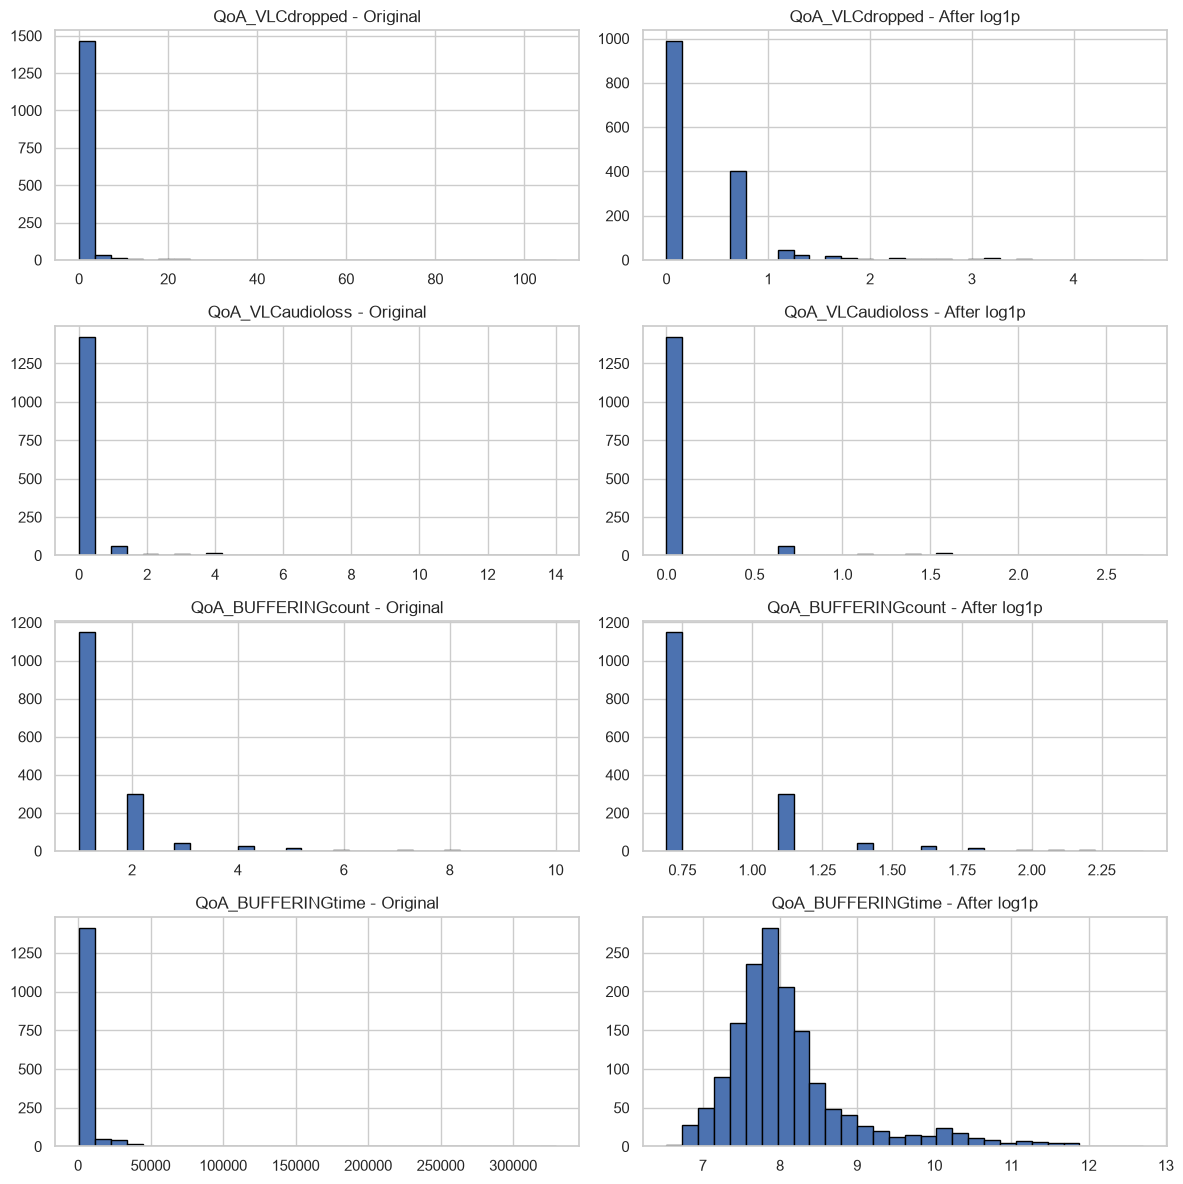

In [17]:
def make_preprocessor(feature_cols):

    nominal = [c for c in NOMINAL_COLS if c in feature_cols]
    skewed = [c for c in SKEWED_COLS if c in feature_cols]
    numeric = [c for c in feature_cols if c not in nominal + skewed]

    return ColumnTransformer([
        ("skewed", Pipeline([
            ("log", FunctionTransformer(np.log1p)),
            ("scale", StandardScaler())
        ]), skewed),

        ("numeric", StandardScaler(), numeric),

        ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal)
    ])
# Compare distributions before and after log transformation
fig, axes = plt.subplots(len(SKEWED_COLS), 2, figsize=(12, 12))

for i, col in enumerate(SKEWED_COLS):
    axes[i, 0].hist(df[col], bins=30, edgecolor="black")
    axes[i, 0].set_title(f"{col} - Original")

    axes[i, 1].hist(np.log1p(df[col]), bins=30, edgecolor="black")
    axes[i, 1].set_title(f"{col} - After log1p")

plt.tight_layout()
plt.show()

## 5. Models and hyperparameter grids

| Model | Why it is included | Hyperparameter grid |
|---|---|---|
| Dummy (most frequent) | Baseline: any useful model should outperform the majority-class prediction | — |
| k-nearest neighbours (kNN) | Non-parametric model that predicts MOS based on similarities between sessions | `n_neighbors` ∈ {3, 5, 7, 9, 11, 15, 21}, `weights` ∈ {uniform, distance}, `p` ∈ {1, 2} |
| SVC | Tests linear and non-linear (RBF) decision boundaries | `kernel` ∈ {linear, rbf}, `C` ∈ {0.1, 1, 10, 100}, `gamma` ∈ {scale, 0.01, 0.1} (RBF only), `class_weight` ∈ {None, balanced} |
| Decision Tree | Interpretable model that captures non-linear relationships and decision rules, such as buffering thresholds | `max_depth` ∈ {3, 5, 7, 10, None}, `min_samples_leaf` ∈ {1, 5, 10, 20}, `class_weight` ∈ {None, balanced} |
| Random Forest | Ensemble of independently trained decision trees; helps reduce variance and improve generalization | `n_estimators` ∈ {100, 200}, `max_depth` ∈ {None, 10, 20}, `min_samples_leaf` ∈ {1, 5}, `class_weight` ∈ {None, balanced} |
| XGBoost | Gradient-boosted trees that sequentially correct previous errors; often effective on tabular data | `max_depth` ∈ {2, 3, 5}, `learning_rate` ∈ {0.05, 0.1, 0.2}, `n_estimators` ∈ {50, 100, 200}, `subsample` ∈ {0.8, 1.0} |


Class weighting is tested for SVC, Decision Tree and Random Forest using
`class_weight` ∈ {None, balanced}, to assess its impact on minority-class
prediction. It is not directly included in the XGBoost grid; therefore,
class weighting is not applied uniformly across all models.

In [ ]:
# Define candidate models and their hyperparameter grids.
# GridSearchCV will test the different configurations using cross-validation.

MODELS = {

    # Dummy Classifier: baseline that always predicts the most frequent class.
    "Dummy": (
        DummyClassifier(strategy="most_frequent"),
        {}
    ),

    # kNN: predicts the class based on the nearest training samples.
    
    "kNN": (
        KNeighborsClassifier(),
        {
            "clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
            "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2]
        }
    ),

    # SVC: separates the MOS classes using decision boundaries.

    "SVC": (
        SVC(random_state=SEED),
        [
            {
                "clf__kernel": ["linear"],
                "clf__C": [0.1, 1, 10, 100],
                "clf__class_weight": [None, "balanced"]
            },
            {
                "clf__kernel": ["rbf"],
                "clf__C": [0.1, 1, 10, 100],
                "clf__gamma": ["scale", 0.01, 0.1],
                "clf__class_weight": [None, "balanced"]
            }
        ]
    ),

    # Decision Tree: learns decision rules from input features.
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {
            "clf__max_depth": [3, 5, 7, 10, None],
            "clf__min_samples_leaf": [1, 5, 10, 20],
            "clf__class_weight": [None, "balanced"]
        }
    ),

    # Random Forest: combines multiple independently trained decision trees.
  
    "Random Forest": (
        RandomForestClassifier(
            random_state=SEED,
            n_jobs=1
        ),
        {
            "clf__n_estimators": [100, 200],
            "clf__max_depth": [None, 10, 20],
            "clf__min_samples_leaf": [1, 5],
            "clf__class_weight": [None, "balanced"]
        }
    ),

    # XGBoost: combines decision trees built sequentially to correct previous errors.
    
    "XGBoost": (
        xgb.XGBClassifier(
            random_state=SEED,
            n_jobs=1,
            eval_metric="mlogloss"
        ),
        {
            "clf__max_depth": [2, 3, 5],
            "clf__learning_rate": [0.05, 0.1, 0.2],
            "clf__n_estimators": [50, 100, 200],
            "clf__subsample": [0.8, 1.0]
        }
    )
}

# Define the evaluation metrics.
# Macro-F1 is used as the main metric for model selection.

SELECTION_METRIC = "f1_macro"

SCORING = {
    "f1_macro": "f1_macro",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "mae": "neg_mean_absolute_error"
}

In [19]:
# Store fitted GridSearchCV objects and their results
searches = {}
results = []

# Train and evaluate each model on both feature sets
for fs_name, cols in FEATURE_SETS.items():

    for model_name, (estimator, grid) in MODELS.items():

        # Build a pipeline with preprocessing and the classifier
        pipe = Pipeline([
            ("prep", make_preprocessor(cols)),
            ("clf", estimator)
        ])

        # Configure hyperparameter search using grouped cross-validation
        search = GridSearchCV(
            estimator=pipe,
            param_grid=grid,
            scoring=SCORING,
            refit=SELECTION_METRIC,
            cv=cv,
            n_jobs=-1,
            return_train_score=True,
            verbose=1
        )

        # Fit the model using training data and user groups
        search.fit(
            X_train[cols],
            y_train,
            groups=groups_train
        )

        # Store the fitted search object
        searches[fs_name, model_name] = search

        # Get the best configuration and its scores
        best_idx = search.best_index_

        best_params = {
            k.removeprefix("clf__"): v
            for k, v in search.best_params_.items()
        }

        results.append({
            "Feature set": fs_name,
            "Model": model_name,
            "CV Macro-F1": search.best_score_,
            "Train Macro-F1": search.cv_results_["mean_train_f1_macro"][best_idx],
            "Best parameters": best_params
        })

        print(
            f"[{fs_name:13s}] {model_name:15s} "
            f"CV Macro-F1 = {search.best_score_:.3f}"
        )

# Create a summary table to compare all models
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV Macro-F1",
    ascending=False
).reset_index(drop=True)

display(results_df)

Fitting 5 folds for each of 1 candidates, totalling 5 fits
[objective    ] Dummy           CV Macro-F1 = 0.135
Fitting 5 folds for each of 28 candidates, totalling 140 fits
[objective    ] kNN             CV Macro-F1 = 0.464
Fitting 5 folds for each of 32 candidates, totalling 160 fits
[objective    ] SVC             CV Macro-F1 = 0.450
Fitting 5 folds for each of 40 candidates, totalling 200 fits
[objective    ] Decision Tree   CV Macro-F1 = 0.466
Fitting 5 folds for each of 24 candidates, totalling 120 fits
[objective    ] Random Forest   CV Macro-F1 = 0.495
Fitting 5 folds for each of 54 candidates, totalling 270 fits
[objective    ] XGBoost         CV Macro-F1 = 0.489
Fitting 5 folds for each of 1 candidates, totalling 5 fits
[with_feedback] Dummy           CV Macro-F1 = 0.135
Fitting 5 folds for each of 28 candidates, totalling 140 fits
[with_feedback] kNN             CV Macro-F1 = 0.629
Fitting 5 folds for each of 32 candidates, totalling 160 fits
[with_feedback] SVC             

,Feature set,Model,CV Macro-F1,Train Macro-F1,Best parameters
0,with_feedback,XGBoost,0.770066,0.877205,"{'learning_rate': 0.2, 'max_depth': 2, 'n_esti..."
1,with_feedback,Random Forest,0.760176,0.943564,"{'class_weight': 'balanced', 'max_depth': 10, ..."
2,with_feedback,Decision Tree,0.747602,0.790697,"{'class_weight': 'balanced', 'max_depth': 5, '..."
3,with_feedback,SVC,0.729186,0.881348,"{'C': 1, 'class_weight': 'balanced', 'gamma': ..."
4,with_feedback,kNN,0.628636,1.000000,"{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}"
5,objective,Random Forest,0.495409,0.982179,"{'class_weight': 'balanced', 'max_depth': None..."
6,objective,XGBoost,0.489094,0.996063,"{'learning_rate': 0.2, 'max_depth': 5, 'n_esti..."
7,objective,Decision Tree,0.465534,0.574021,"{'class_weight': None, 'max_depth': None, 'min..."
8,objective,kNN,0.463963,1.000000,"{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}"
9,objective,SVC,0.449718,0.652285,"{'C': 1, 'class_weight': 'balanced', 'gamma': ..."


## 6. Results

### 6.1 Cross-validated comparison (training users only)

In [ ]:
# Collect cross-validation results for all models and feature sets

rows = []
for (fs_name, model_name), s in searches.items():
    i = s.best_index_
    r = s.cv_results_
    rows.append({
        "feature_set": fs_name, "model": model_name,
        "cv_f1_macro": r["mean_test_f1_macro"][i], "cv_f1_macro_std": r["std_test_f1_macro"][i],
        "cv_accuracy": r["mean_test_accuracy"][i], "cv_accuracy_std": r["std_test_accuracy"][i],
        "cv_mae": -r["mean_test_mae"][i], "cv_mae_std": r["std_test_mae"][i],
        "best_params": {k.removeprefix("clf__"): v for k, v in s.best_params_.items()},
    })
cv_summary = pd.DataFrame(rows)
cv_summary.to_csv(RESULTS_DIR / "cv_summary.csv", index=False)
cv_summary.round(3)

,feature_set,model,cv_f1_macro,cv_f1_macro_std,cv_accuracy,cv_accuracy_std,cv_mae,cv_mae_std,best_params
0,objective,Dummy,0.135,0.002,0.507,0.010,0.690,0.016,{}
1,objective,kNN,0.464,0.011,0.521,0.016,0.592,0.026,"{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}"
2,objective,SVC,0.450,0.030,0.417,0.043,0.706,0.040,"{'C': 1, 'class_weight': 'balanced', 'gamma': ..."
3,objective,Decision Tree,0.466,0.033,0.531,0.038,0.539,0.041,"{'class_weight': None, 'max_depth': None, 'min..."
4,objective,Random Forest,0.495,0.024,0.509,0.020,0.591,0.019,"{'class_weight': 'balanced', 'max_depth': None..."
5,objective,XGBoost,0.489,0.016,0.553,0.019,0.528,0.027,"{'learning_rate': 0.2, 'max_depth': 5, 'n_esti..."
6,with_feedback,Dummy,0.135,0.002,0.507,0.010,0.690,0.016,{}
7,with_feedback,kNN,0.629,0.044,0.711,0.013,0.319,0.009,"{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}"
8,with_feedback,SVC,0.729,0.026,0.771,0.022,0.245,0.028,"{'C': 1, 'class_weight': 'balanced', 'gamma': ..."
9,with_feedback,Decision Tree,0.748,0.039,0.769,0.050,0.252,0.060,"{'class_weight': 'balanced', 'max_depth': 5, '..."


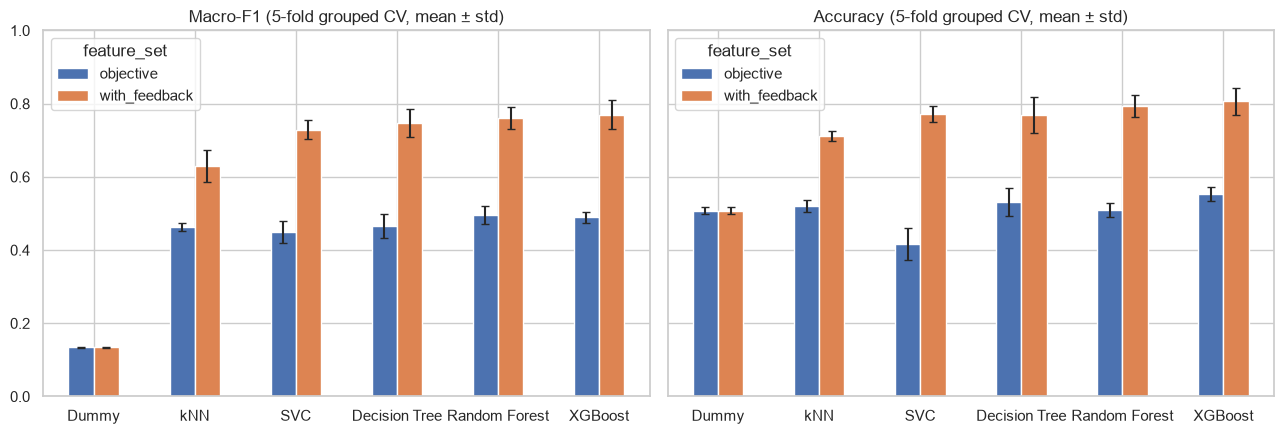

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (metric, label) in zip(axes, [("cv_f1_macro", "Macro-F1"), ("cv_accuracy", "Accuracy")]):
    pivot = cv_summary.pivot(index="model", columns="feature_set", values=metric).loc[list(MODELS)]
    err = cv_summary.pivot(index="model", columns="feature_set", values=f"{metric}_std").loc[list(MODELS)]
    pivot.plot.bar(yerr=err, ax=ax, capsize=3, rot=0)
    ax.set(title=f"{label} (5-fold grouped CV, mean ± std)", xlabel="", ylim=(0, 1))
fig.tight_layout()
save_fig(fig, "cv_comparison")
plt.show()

### 6.2 Hyperparameter sensitivity

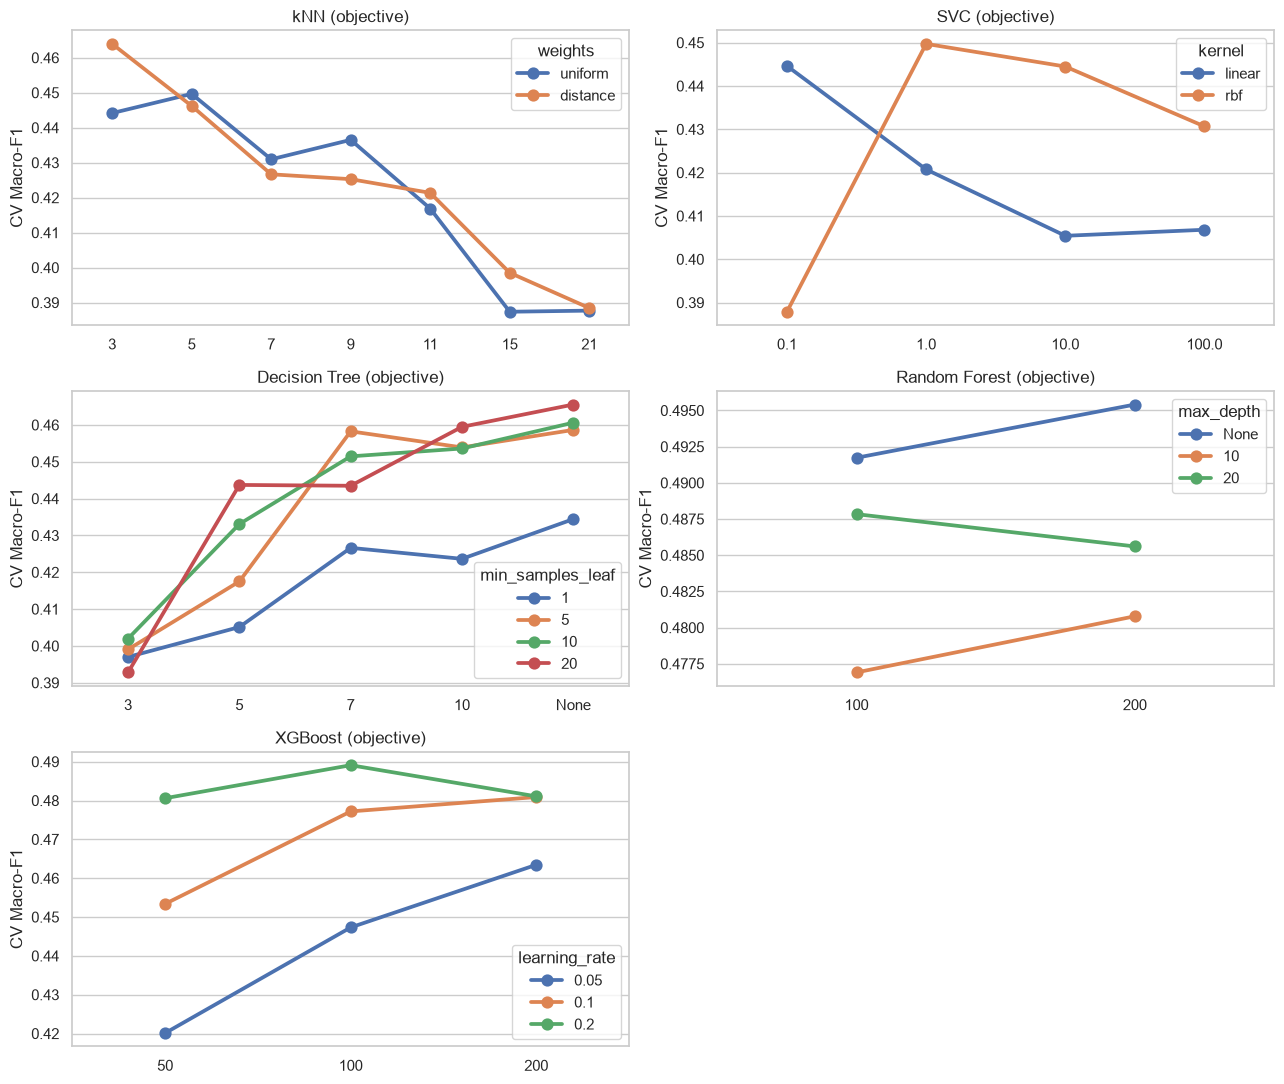

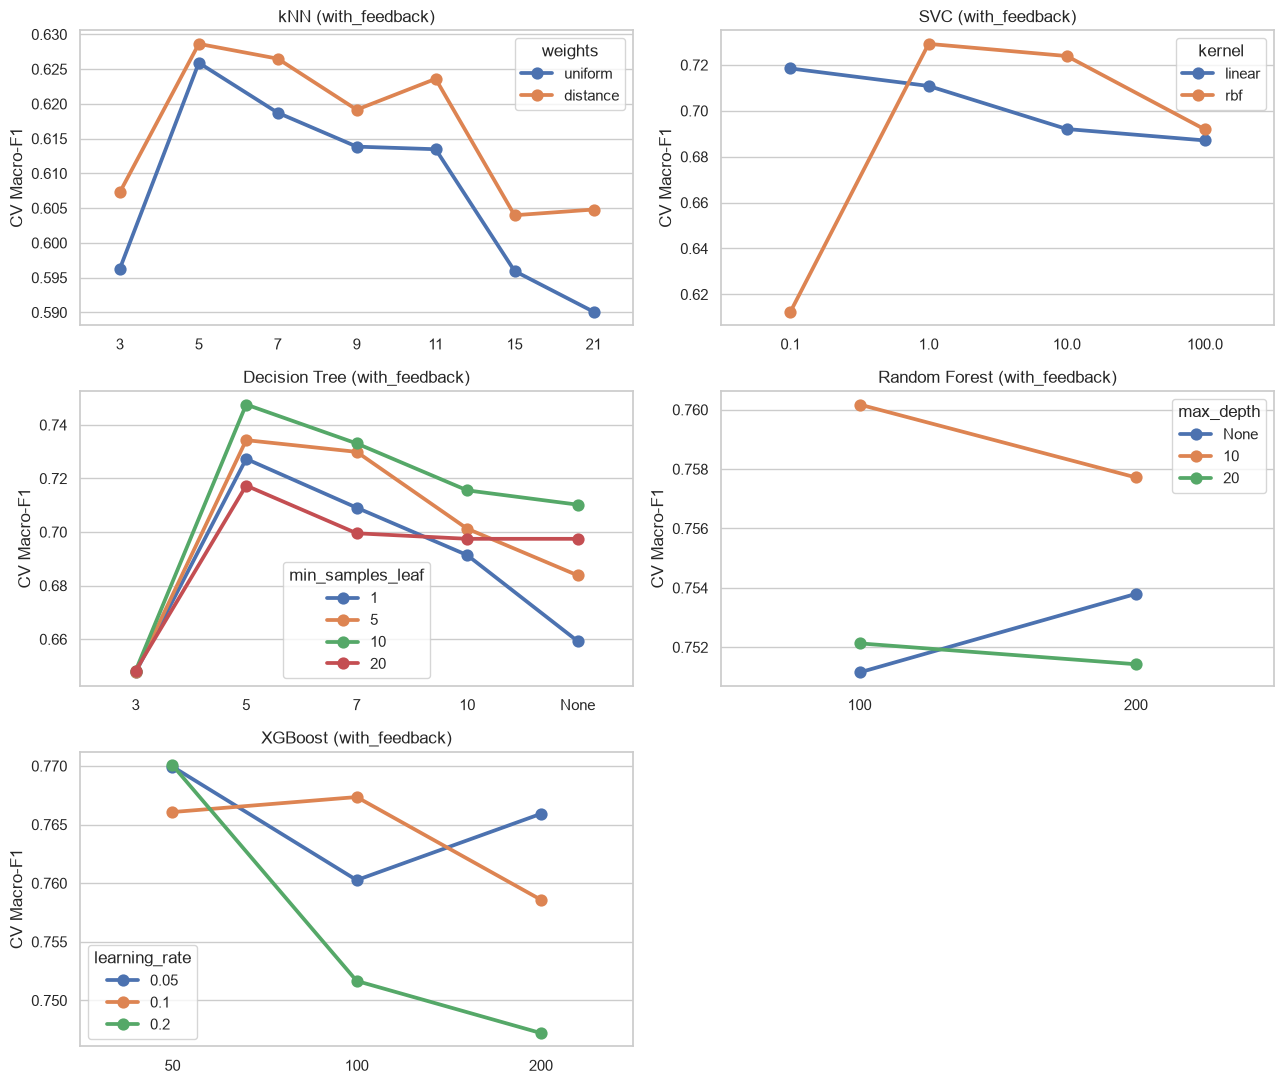

In [23]:
def plot_sensitivity(fs_name, model_name, x, hue, ax, fixed=None):

    # Retrieve cross-validation results
    res = pd.DataFrame(searches[fs_name, model_name].cv_results_)

    # Keep only the selected parameter values, if specified
    for k, v in (fixed or {}).items():
        res = res[res[f"param_clf__{k}"] == v]

    # Convert parameter values to strings for plotting
    res = res.assign(**{
        c: res[f"param_clf__{c}"].astype(object).fillna("None").astype(str)
        for c in (x, hue)
    })

    # Keep the best Macro-F1 score for each parameter combination
    best = (
        res.groupby([x, hue], sort=False)["mean_test_f1_macro"]
        .max()
        .reset_index()
    )

    # Plot the results
    sns.pointplot(
        data=best,
        x=x,
        y="mean_test_f1_macro",
        hue=hue,
        ax=ax
    )

    ax.set(
        title=f"{model_name} ({fs_name})",
        ylabel="CV Macro-F1",
        xlabel=""
    )


# Generate sensitivity plots for both feature sets
for fs_name in FEATURE_SETS:

    fig, axes = plt.subplots(3, 2, figsize=(13, 11))

    # kNN: number of neighbors and distance weighting
    plot_sensitivity(
        fs_name, "kNN",
        "n_neighbors", "weights",
        axes[0, 0]
    )

    # SVC: regularization parameter and kernel
    plot_sensitivity(
        fs_name, "SVC",
        "C", "kernel",
        axes[0, 1]
    )

    # Decision Tree: tree depth and minimum leaf size
    plot_sensitivity(
        fs_name, "Decision Tree",
        "max_depth", "min_samples_leaf",
        axes[1, 0]
    )

    # Random Forest: number of trees and maximum tree depth
    plot_sensitivity(
        fs_name, "Random Forest",
        "n_estimators", "max_depth",
        axes[1, 1]
    )

    # XGBoost: number of trees and learning rate
    plot_sensitivity(
        fs_name, "XGBoost",
        "n_estimators", "learning_rate",
        axes[2, 0]
    )

    # Hide the unused subplot
    axes[2, 1].axis("off")

    fig.tight_layout()
    save_fig(fig, f"sensitivity_{fs_name}")
    plt.show()

### 6.3 Final evaluation on held-out test users

For each feature set and each candidate model, the best hyperparameter configuration selected through cross-validation is refitted on the entire training set. This is handled automatically by `GridSearchCV(refit=SELECTION_METRIC)`.

Each refitted model is then evaluated **once** on the held-out test users. All candidate models are reported for transparency, while model selection is based exclusively on cross-validation Macro-F1 scores. The test set is therefore kept independent of hyperparameter tuning and model selection.

In [25]:
from sklearn.metrics import balanced_accuracy_score
# Evaluate all models on the held-out test set
test_rows = []

for (fs_name, model_name), s in searches.items():

    # Predict MOS labels on unseen test users
    pred = s.predict(X_test[FEATURE_SETS[fs_name]])

    # Compute test performance metrics
    test_rows.append({
        "feature_set": fs_name,
        "model": model_name,
        "test_f1_macro": f1_score(y_test, pred, average="macro"),
        "test_accuracy": accuracy_score(y_test, pred),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "test_mae": mean_absolute_error(y_test, pred),
    })

# Create the test results summary
test_summary = pd.DataFrame(test_rows)


# Identify the best model for each feature set based on CV Macro-F1
champions = cv_summary.loc[
    cv_summary.groupby("feature_set")["cv_f1_macro"].idxmax(),
    ["feature_set", "model"]
]

# Mark the models selected through cross-validation
test_summary["selected_by_cv"] = test_summary.set_index(
    ["feature_set", "model"]
).index.isin(
    champions.set_index(["feature_set", "model"]).index
)

# Save and display the final test results
test_summary.to_csv(RESULTS_DIR / "test_summary.csv", index=False)

display(test_summary.round(3))

,feature_set,model,test_f1_macro,test_accuracy,test_balanced_accuracy,test_mae,selected_by_cv
0,objective,Dummy,0.135,0.510,0.200,0.684,False
1,objective,kNN,0.343,0.454,0.334,0.684,False
2,objective,SVC,0.355,0.342,0.396,0.812,False
3,objective,Decision Tree,0.447,0.513,0.440,0.572,False
4,objective,Random Forest,0.435,0.461,0.441,0.651,True
5,objective,XGBoost,0.368,0.516,0.365,0.553,False
6,with_feedback,Dummy,0.135,0.510,0.200,0.684,False
7,with_feedback,kNN,0.538,0.651,0.511,0.408,False
8,with_feedback,SVC,0.633,0.704,0.651,0.332,False
9,with_feedback,Decision Tree,0.705,0.760,0.726,0.260,False


=== Random Forest on 'objective' features ===
              precision    recall  f1-score   support

           1      0.562     0.500     0.529        18
           2      0.391     0.391     0.391        23
           3      0.273     0.438     0.336        48
           4      0.687     0.510     0.585       155
           5      0.301     0.367     0.331        60

    accuracy                          0.461       304
   macro avg      0.443     0.441     0.435       304
weighted avg      0.516     0.461     0.478       304

=== XGBoost on 'with_feedback' features ===
              precision    recall  f1-score   support

           1      0.688     0.611     0.647        18
           2      0.560     0.609     0.583        23
           3      0.610     0.521     0.562        48
           4      0.806     0.858     0.831       155
           5      0.772     0.733     0.752        60

    accuracy                          0.747       304
   macro avg      0.687     0.666     0.6

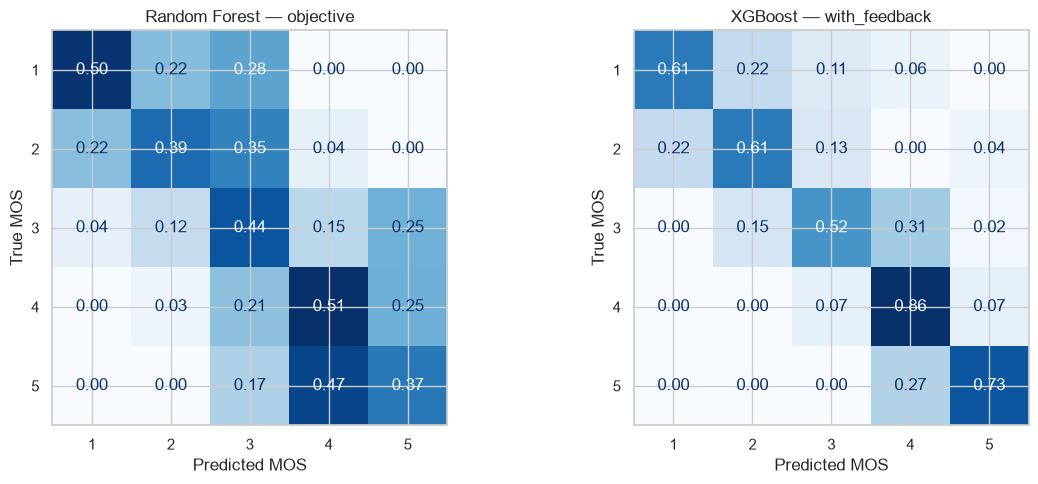

In [26]:
fig, axes = plt.subplots(1, len(champions), figsize=(12, 5))
for ax, (_, row) in zip(axes, champions.iterrows()):
    s = searches[row.feature_set, row.model]
    pred = s.predict(X_test[FEATURE_SETS[row.feature_set]])
    ConfusionMatrixDisplay.from_predictions(y_test + 1, pred + 1, normalize="true", values_format=".2f",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=f"{row.model} — {row.feature_set}", xlabel="Predicted MOS", ylabel="True MOS")
    print(f"=== {row.model} on '{row.feature_set}' features ===")
    print(classification_report(y_test + 1, pred + 1, digits=3, zero_division=0))
fig.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

### 6.4 Which factors drive the predictions?

Permutation importance of the selected models on the test users (drop in macro-F1 when a column is shuffled,
10 repeats). It is computed on the raw input columns, so one-hot encoded variables are assessed as a whole.

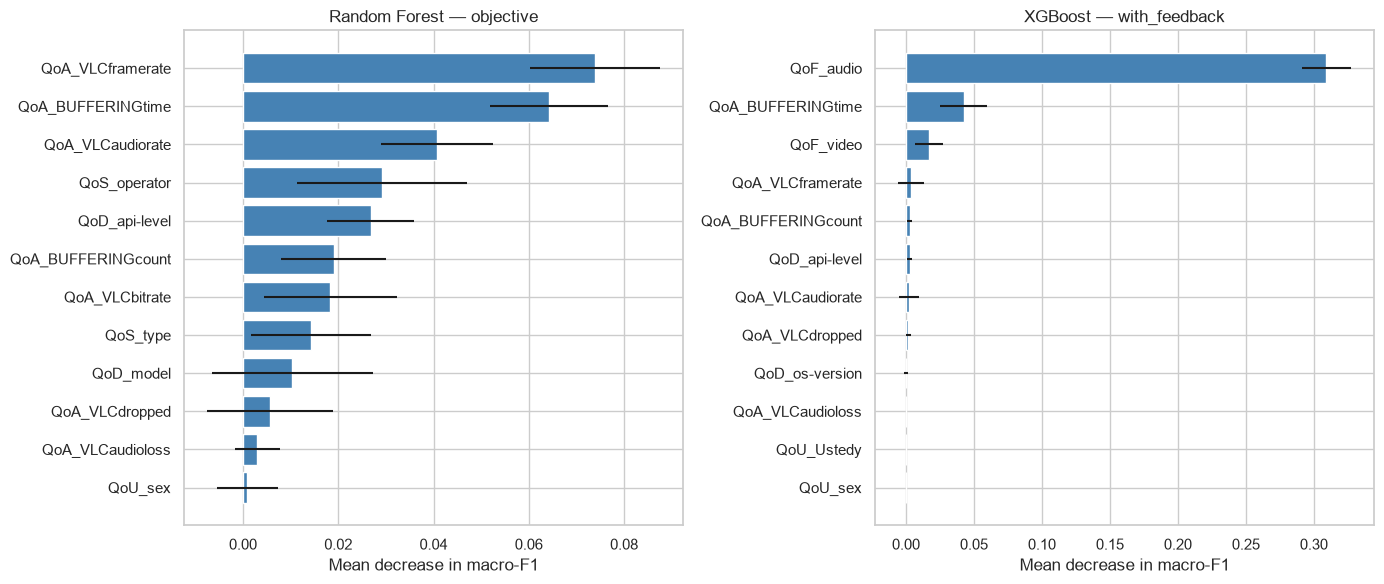

In [28]:
fig, axes = plt.subplots(1, len(champions), figsize=(14, 6))
for ax, (_, row) in zip(axes, champions.iterrows()):
    cols = FEATURE_SETS[row.feature_set]
    pi = permutation_importance(searches[row.feature_set, row.model].best_estimator_, X_test[cols], y_test,
                                scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values().tail(12)
    ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=cols)[imp.index], color="steelblue")
    ax.set(title=f"{row.model} — {row.feature_set}", xlabel="Mean decrease in macro-F1")
fig.tight_layout()
save_fig(fig, "permutation_importance")
plt.show()

### 6.5 Does grouping by user matter?

The selected configurations are re-evaluated on the **training users only** (the test set stays untouched)
with repeated 5-fold CV (5 repetitions), once with folds stratified on MOS only (`random`) and once with folds
grouped by user (`grouped`).

In [29]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Compare random and user-grouped cross-validation strategies
rows = []

for _, row in champions.iterrows():

    # Retrieve the selected feature set and model
    cols = FEATURE_SETS[row.feature_set]
    est = clone(searches[row.feature_set, row.model].best_estimator_)

    # Compare the two splitting strategies
    for split, splitter in [
        ("random", StratifiedKFold),
        ("grouped", StratifiedGroupKFold)
    ]:

        # Repeat cross-validation with different random seeds
        for rep in range(5):

            cv_rep = splitter(
                n_splits=CV_FOLDS,
                shuffle=True,
                random_state=SEED + rep
            )

            # Evaluate the model using cross-validation
            r = cross_validate(
                est,
                X_train[cols],
                y_train,
                cv=cv_rep,
                n_jobs=-1,
                groups=groups_train if split == "grouped" else None,
                scoring=["f1_macro", "accuracy"]
            )

            # Store the fold scores
            rows.extend([
                {
                    "feature_set": row.feature_set,
                    "model": row.model,
                    "split": split,
                    "f1_macro": f,
                    "accuracy": a
                }
                for f, a in zip(
                    r["test_f1_macro"],
                    r["test_accuracy"]
                )
            ])

# Aggregate results across folds and repetitions
split_effect = (
    pd.DataFrame(rows)
    .groupby(["feature_set", "model", "split"])
    .agg(
        f1_macro=("f1_macro", "mean"),
        f1_macro_std=("f1_macro", "std"),
        accuracy=("accuracy", "mean"),
        accuracy_std=("accuracy", "std")
    )
    .reset_index()
)

# Save and display results
split_effect.to_csv(
    RESULTS_DIR / "split_effect.csv",
    index=False
)

display(split_effect.round(3))

,feature_set,model,split,f1_macro,f1_macro_std,accuracy,accuracy_std
0,objective,Random Forest,grouped,0.481,0.043,0.502,0.032
1,objective,Random Forest,random,0.522,0.027,0.532,0.021
2,with_feedback,XGBoost,grouped,0.765,0.039,0.804,0.026
3,with_feedback,XGBoost,random,0.762,0.038,0.803,0.026


### Interpretation of the experimental results

The experiments highlight the importance of feature selection, validation strategy and model choice for MOS prediction.

**1. Subjective feedback substantially improves prediction performance.**

Adding QoF subjective ratings leads to a clear improvement across all tested models. On the held-out test set, the model selected through cross-validation for the `with_feedback` feature set (XGBoost) achieves a Macro-F1 of 0.675, an accuracy of 0.747, a balanced accuracy of 0.666 and a MAE of 0.276.

In comparison, the selected model for the `objective` feature set (Random Forest) achieves a Macro-F1 of 0.435, an accuracy of 0.461, a balanced accuracy of 0.441 and a MAE of 0.651.

This suggests that QoF ratings provide valuable information about overall perceived video quality. The permutation importance analysis also identifies `QoF_audio` as a particularly influential feature, consistent with the strong Spearman correlation with MOS observed during EDA (0.84).

However, this improvement must be interpreted carefully: QoF ratings are subjective assessments that may be collected after or during the viewing experience. Their availability in a real-time prediction scenario cannot be assumed. Therefore, the objective-only setting remains the more relevant scenario for predicting QoE from measurable technical and contextual information.

**2. Objective features provide limited but useful predictive information.**

Without subjective feedback, Random Forest is selected through cross-validation and achieves a test Macro-F1 of 0.435. This is substantially higher than the Dummy baseline (0.135), indicating that the model captures information beyond simply predicting the majority class.

However, its test accuracy (0.461) is lower than the Dummy accuracy (0.510). This illustrates why accuracy alone is insufficient for this imbalanced dataset: a majority-class classifier can obtain relatively high accuracy while failing to recognize minority MOS classes.

The permutation importance analysis suggests that buffering time is the most influential objective feature, followed by audio rate, frame rate and video bitrate. This indicates that player-level QoA measurements provide more predictive information than network and device descriptors in this experiment.

**3. Cross-validation selection and test-set ranking are not identical.**

Random Forest is selected for the objective feature set, while XGBoost is selected for the with-feedback feature set, based on their respective cross-validation Macro-F1 scores.

Nevertheless, Decision Tree obtains slightly higher test scores than the selected model in both settings. For example, it achieves a test Macro-F1 of 0.447 with objective features and 0.705 with feedback features.

This difference illustrates the variability associated with a single held-out test split. The predefined cross-validation selection procedure is therefore retained, rather than selecting models retrospectively based on test performance.

**4. The grouped validation strategy reveals a possible user-overlap effect.**

The repeated cross-validation experiment shows that the splitting strategy affects performance differently depending on the feature set.

With objective features, random cross-validation achieves a mean Macro-F1 of 0.522, compared with 0.481 for grouped cross-validation. Accuracy decreases from 0.532 to 0.502 when users are kept separate.

This suggests that random splitting may produce somewhat optimistic estimates when multiple sessions from the same users are distributed across training and validation folds.

With subjective feedback, the two strategies produce very similar results: Macro-F1 is 0.762 with random splitting and 0.765 with grouped splitting, while accuracy is 0.803 and 0.804, respectively.

The difference is descriptive and does not establish statistical significance. Nevertheless, grouped cross-validation remains the preferred strategy because the intended use case is prediction for previously unseen users.

**5. Model errors and class-level performance require further attention.**

Global metrics do not fully describe how well the models recognize each MOS category. The confusion matrices and classification reports are therefore used to examine class-specific precision, recall and F1-scores.

Particular attention should be given to MOS 1 and MOS 2, which represent relatively small proportions of the dataset. Errors between neighbouring MOS classes should also be distinguished from larger prediction errors, since MOS is an ordinal target.

These results help determine whether the models can identify poor-quality experiences rather than mainly recognizing the more frequent MOS 4 class.

**6. Hyperparameter selection reflects differences in model complexity.**

The selected hyperparameters provide additional insight into how each algorithm models the relationship between input features and MOS. However, the best configurations should be interpreted as the best values within the tested grids, not necessarily as global optima.

The cross-validation results, rather than the held-out test scores, remain the basis for hyperparameter and model selection.

## 8. Reproducibility

- Data: downloaded from `DATA_URL` (cell 1) into `data/pokemon.csv` on first run.
- Seeds: `SEED = 42` controls the train/test split, the CV folds, SVC, the decision tree, XGBoost, Random Forest and
  permutation importance.
- Split: 80/20 grouped and stratified (`StratifiedGroupKFold`, first of 5 folds). Tuning uses 5-fold grouped CV
  on the training part only.
- Hyperparameter grids: Section 5. Best parameters: `results/cv_summary.csv`; test scores:
  `results/test_summary.csv`; grouped vs random CV: `results/split_effect.csv`.
- Software versions: printed in cell 1; pinned in `requirements.txt`.